# Wastewater Process Optimization — Synthetic Pilot Analysis

**Portfolio demonstration only.** No real plant data or regulatory compliance determination. This notebook tests hypotheses on fabricated baseline/pilot observations and compares economics to a charter target.


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
p = Path('/content/synthetic_wastewater_baseline.csv')
if not p.exists():
    p = Path('/content/synthetic_wastewater_baseline.csv')
df = pd.read_csv(p)
print(df.groupby('phase')[['flow_m3_day','energy_kwh_m3','chem_cost_usd_m3','effluent_index']].agg(['mean','std']).round(3))

                   flow_m3_day         energy_kwh_m3        chem_cost_usd_m3  \
                          mean     std          mean    std             mean   
phase                                                                          
baseline              1500.777  62.593         0.715  0.044            0.281   
illustrative_pilot    1503.643  68.094         0.551  0.046            0.136   

                          effluent_index         
                      std           mean    std  
phase                                            
baseline            0.017          0.674  0.062  
illustrative_pilot  0.017          0.622  0.052  


## **Define, Measure, Analyze**

Compare energy and reagent-intensity statistics for two simulated periods. Differences are descriptive and **not causal evidence**, because neither data-generating process nor operating conditions represents a real randomized pilot.


energy_kwh_m3: baseline=0.715, pilot=0.551,  change=-23.0%
chem_cost_usd_m3: baseline=0.281, pilot=0.136,  change=-51.5%
effluent_index: baseline=0.674, pilot=0.622,  change=-7.8%


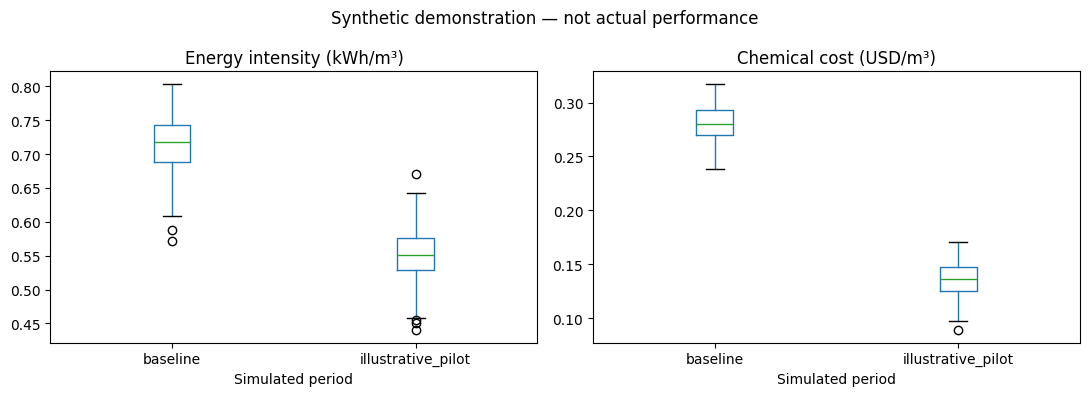

In [15]:
summary=df.groupby('phase')[['energy_kwh_m3','chem_cost_usd_m3','effluent_index']].mean()
base=summary.loc['baseline']; pilot=summary.loc['illustrative_pilot']
for metric in summary.columns:
    delta=(pilot[metric]/base[metric]-1)*100

    print(f'{metric}: baseline={base[metric]:.3f}, '

          f'pilot={pilot[metric]:.3f},  change={delta:+.1f}%')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,metric,title in zip(axs,['energy_kwh_m3','chem_cost_usd_m3'],
 ['Energy intensity (kWh/m³)','Chemical cost (USD/m³)']):
    df.boxplot(column=metric,by='phase',ax=ax,grid=False)
    ax.set_title(title);ax.set_xlabel('Simulated period')
plt.suptitle('Synthetic demonstration — not actual performance')
plt.tight_layout();plt.show()

## **Project business case and controls**
The charter assumptions (targeted values) are intentionally separate from the synthetic dataset (illustrative values). Validate the avoided-disposal line item and comparable flow/quality before financial approval.


In [20]:
volume=1500*365
energy_target=(0.72-0.52)*volume*0.14
chemical_target=(0.28-0.10)*volume
assumed_rework_avoidance=61000
project_cost=160000
annual_target=energy_target+chemical_target+assumed_rework_avoidance
results = {
    "annual_targeted_gross_benefit_USD " : round(annual_target),
    "cost_baseline_USD ": project_cost,
    "simple_first_year_BCR": round(annual_target/project_cost,2),
    "simple_payback_years": round(project_cost/annual_target,2)
}
for key, val in results.items():
   print(f"{key}: {val}")

annual_targeted_gross_benefit_USD : 174880
cost_baseline_USD : 160000
simple_first_year_BCR: 1.09
simple_payback_years: 0.91


## **Control plan**

Track flow-normalized kWh/m³ and reagent $ /m³ weekly, confirm sensor calibration and lab sample quality, monitor all legally applicable permit parameters, and investigate special causes before adjusting control settings. Any actual process adjustment requires qualified site authorization.


## **Results and Business Impact**

### **Statistical and Operational Insights**

This project evaluates a hypothetical industrial wastewater treatment optimization initiative using synthetic baseline and pilot operating data.

The descriptive statistics and boxplot comparisons demonstrate three notable modeled improvements:

- **Energy intensity:** Decreased from 0.715 to 0.551 kWh/m³, representing a 23.0% reduction.

- **Chemical treatment costs:**  Decreased from  $ 0.281  to  $ 0.136 per m³, representing a 51.5% reduction.

- **Effluent index:** Decreased from 0.674 to 0.622, representing a 7.8% reduction, with interpretation dependent on the definition of the index.

Average wastewater throughput remained nearly constant at approximately 1,500 m³/day, indicating that the simulated reductions in energy and chemical consumption were not simply the result of reduced treatment volume.

### **Financial and Business Value**

Using an illustrative treatment capacity of 1,500 m³/day, 365 operating days per year, and an electricity price of $0.12/kWh, the analysis estimates:

| Financial Indicator | Illustrative Result |
|---|---:|
| Annual energy savings | $10,774.80 |
| Annual chemical savings | $79,387.50 |
| Total annual gross savings | $90,162.30 |
| Initial project investment | $160,000 |
| Simple payback period | 1.77 years |

The results demonstrate how engineering performance improvements can be converted into financial indicators to support project prioritization, investment evaluation, and operational decision-making.

### **Project Management and Continuous Improvement**

The analysis integrates PMP-aligned project management principles with Lean Six Sigma DMAIC and data analytics.

Statistical comparisons support the measurement and analysis phases, while cost-benefit calculations support project justification, financial planning, and stakeholder communication.

### **Limitations and Future Development**

All results are derived from synthetic demonstration data and should not be interpreted as actual industrial performance.

Future work will include hypothesis testing, statistical process control, process optimization, engineering validation, financial sensitivity analysis, and verification against applicable wastewater treatment requirements.

**Key takeaway:**

This case study demonstrates how chemical engineering, project management, and data analytics can work together to evaluate potential operating-cost reductions while maintaining attention to process performance and treatment quality.